# Rent Burden — Three Ways to Get a Defensible-Looking Number Wrong

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 2023 5-Year (pinned)

"The share of renters paying more than 30 per cent of income on housing" is one of the most widely
cited statistics in US housing policy. It is published in a table that makes it easy to compute,
and there are at least three separate ways to compute something that looks exactly like it and is
not.

**The denominator.** ACS table B25070 has a category called *Not computed*. It is part of the
total. Divide by the total and you are dividing by a base that includes households the statistic
does not describe.

**The pairing.** Median rent divided by median income is not the median of rent-over-income. The
two medians describe different households, and the widely used version compounds the error by
pairing renters' rent with *all* households' income.

**The aggregation.** A published median for a state is not the average of its counties' medians —
not the simple average, and not quite the population-weighted one either.

All three are demonstrated against the live table, and each one is shown to change not just the
level but the ordering of the country.

Real data only. No synthetic fallback. *Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

1. **Identify** which published rows belong to the distribution being measured and which belong to
   the universe but not the distribution, and **quantify** what dividing by the wrong base costs.
2. **Propagate** margins of error through a derived denominator, recognising that a base you
   construct has a margin you must compute rather than inherit.
3. **Settle** the denominator question against an external figure published by the Bureau itself,
   rather than by argument.
4. **Distinguish** a ratio of medians from the median of a ratio, and measure the disagreement on
   real data under both a correct and an incorrect income universe.
5. **Interpolate** a percentile from bracket counts, and **refuse** to report one that falls in an
   open-ended bracket.
6. **Test** whether a published median can be reconstructed by averaging sub-area medians, under
   both simple and population-weighted averaging.
7. **Recognise** that all three errors preserve the appearance of the statistic while changing the
   ranking of the country.

## Prerequisites

**Knowledge.** D01 (ACS counts and margins), D03 (propagation and significance), and D16 —
`check_partition` from that notebook's data layer is reused here, and the open-bracket guard is the
same pattern as D06's top-share guard.

**Setup.** `CENSUS_API_KEY` in the environment, or in the file `KRL_SECRETS_PATH` points at.

**Packages.** `pandas`, `numpy`, `matplotlib`, and `krl_tutorials_data`.

## Data Provenance

| Table | Variables | Role |
|---|---|---|
| **B25070** | `_001E` total; `_002E`–`_010E` nine rent-burden brackets; `_011E` *Not computed* | the distribution |
| **B25064** | `_001E` median gross rent | numerator of the ratio-of-medians |
| **B25119** | `_003E` median household income, renter-occupied | correct denominator for that ratio |
| **B19013** | `_001E` median household income, all households | the *incorrect* denominator in common use |
| **B25003** | `_003E` renter-occupied households | weights for the aggregation test |
| **DP04** (profile) | `_0141PE`, `_0142PE` | the Bureau's own published burden percentage — external check |

plus the `…M` margin of error for each, at county and state level.

**The nine brackets are the distribution; `_011E` is not.** *Not computed* covers households with
no cash rent and those reporting zero or negative income — cases where rent as a percentage of
income has no value, not cases where the value is low. It sits inside `_001E` all the same. The
first analytical cell tests that arithmetic rather than assuming it.

**Thirty per cent is an exact bracket edge.** `_006E` ends at 29.9 and `_007E` begins at 30.0, so
the burdened count needs no interpolation. A threshold of 33 or 35 per cent would, and would carry
an assumption this one does not.

In [1]:
"""Configuration. Bracket structure is declared, not inferred from variable order."""
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src")); break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.sources import fetch_acs, DataAccessError
from krl_tutorials_data.uncertainty import (
    Estimate, aggregate_moe, proportion_moe, difference_is_significant,
)
from krl_tutorials_data.tabulation import check_partition, Coverage
from krl_tutorials_data.brackets import (
    ACS_B25070_BRACKETS, interpolated_percentile, median_from_brackets,
    percentile_is_identified, UnidentifiedPercentileError,
)

ACS_VINTAGE = 2023
BURDEN_THRESHOLD = 30.0

BRACKET_CODES = tuple(f"B25070_{i:03d}E" for i in range(2, 11))
UNIVERSE = "B25070_001E"
NOT_COMPUTED = "B25070_011E"

MEDIAN_RENT = "B25064_001E"
MEDIAN_INCOME_RENTERS = "B25119_003E"
MEDIAN_INCOME_ALL = "B19013_001E"
RENTER_HOUSEHOLDS = "B25003_003E"

BRACKETS = ACS_B25070_BRACKETS
# Brackets at or above the threshold. Computed from the declared edges, so a
# change of threshold cannot silently disagree with the arithmetic below.
BURDENED_IDX = [i for i, lo in enumerate(BRACKETS.lower) if lo >= BURDEN_THRESHOLD]

pd.set_option("display.width", 150)
plt.rcParams["figure.dpi"] = 110

print(f"Vintage            : ACS {ACS_VINTAGE} 5-Year (pinned)")
print(f"Burden threshold   : {BURDEN_THRESHOLD:g} {BRACKETS.units}")
print(f"Brackets           : {BRACKETS.n} (top open-ended: {BRACKETS.top_is_open})")
print(f"Burdened brackets  : {len(BURDENED_IDX)} of {BRACKETS.n}, "
      f"starting at {BRACKETS.lower[BURDENED_IDX[0]]:g}")
print(f"Threshold is an exact bracket edge: "
      f"{BURDEN_THRESHOLD in BRACKETS.lower}")

Vintage            : ACS 2023 5-Year (pinned)
Burden threshold   : 30 percent of household income
Brackets           : 9 (top open-ended: True)
Burdened brackets  : 4 of 9, starting at 30
Threshold is an exact bracket edge: True


In [2]:
VARIABLES = {UNIVERSE: "Estimate!!Total: (renter-occupied households)"}
for _i, _code in enumerate(BRACKET_CODES):
    _lo, _hi = BRACKETS.lower[_i], BRACKETS.upper[_i]
    VARIABLES[_code] = (
        f"Estimate!!Total:!!{_lo:.1f} percent or more"
        if not np.isfinite(_hi)
        else f"Estimate!!Total:!!{_lo:.1f} to {_hi - 0.1:.1f} percent"
    )
VARIABLES[NOT_COMPUTED] = "Estimate!!Total:!!Not computed"
VARIABLES[MEDIAN_RENT] = "Estimate!!Median gross rent"
VARIABLES[MEDIAN_INCOME_RENTERS] = (
    "Estimate!!Median household income in the past 12 months "
    "(in 2023 inflation-adjusted dollars) --!!Total:!!Renter occupied (dollars)"
)
VARIABLES[MEDIAN_INCOME_ALL] = (
    "Estimate!!Median household income in the past 12 months "
    "(in 2023 inflation-adjusted dollars)"
)
VARIABLES[RENTER_HOUSEHOLDS] = "Estimate!!Total:!!Renter occupied"
VARIABLES.update({c[:-1] + "M": "Margin of Error for " + l
                  for c, l in list(VARIABLES.items())})

try:
    counties, prov_county = fetch_acs(
        year=ACS_VINTAGE, variables=VARIABLES, geography="county:*")
    states, prov_state = fetch_acs(
        year=ACS_VINTAGE, variables=VARIABLES, geography="state:*")
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    print("\nNo synthetic fallback exists by design.")
    raise

print(f"Counties : {len(counties)}")
print(f"States   : {len(states)}")
print()
print(prov_county.render())

Counties : 3222
States   : 52

Source      : U.S. Census Bureau - American Community Survey (acs/acs5)
Vintage     : 2023  (pinned)
Endpoint    : https://api.census.gov/data/2023/acs/acs5
Retrieved   : 2026-09-18T12:17:00+00:00
Shape       : 3222 rows x 33 cols
Payload hash: 42d64fff6c221e89...  (canonical-rows)
Data mode   : EMPIRICAL
Variables   :
              B25070_001E      Estimate!!Total: (renter-occupied households)
              B25070_002E      Estimate!!Total:!!0.0 to 9.9 percent
              B25070_003E      Estimate!!Total:!!10.0 to 14.9 percent
              B25070_004E      Estimate!!Total:!!15.0 to 19.9 percent
              B25070_005E      Estimate!!Total:!!20.0 to 24.9 percent
              B25070_006E      Estimate!!Total:!!25.0 to 29.9 percent
              B25070_007E      Estimate!!Total:!!30.0 to 34.9 percent
              B25070_008E      Estimate!!Total:!!35.0 to 39.9 percent
              B25070_009E      Estimate!!Total:!!40.0 to 49.9 percent
             

## 1. The denominator

Two claims to test before computing anything. First, that the nine brackets plus *Not computed*
account for the whole universe — which establishes that *Not computed* really is inside `_001E`.
Second, that the nine brackets alone do **not**, which is what makes the denominator a choice.

In [3]:
def col(df: pd.DataFrame, code: str) -> np.ndarray:
    return pd.to_numeric(df[code], errors="coerce").to_numpy(dtype=float)


bracket_counts = np.column_stack([col(counties, c) for c in BRACKET_CODES])
universe = col(counties, UNIVERSE)
not_computed = col(counties, NOT_COMPUTED)

with_nc = [check_partition([*bracket_counts[i], not_computed[i]], universe[i],
                           label="brackets + not computed")
           for i in range(len(counties)) if universe[i] > 0]
without_nc = [check_partition(list(bracket_counts[i]), universe[i],
                              label="brackets alone")
              for i in range(len(counties)) if universe[i] > 0]

print(f"Counties with a non-zero renter universe: {len(with_nc)} of {len(counties)}")
print(f"  nine brackets + 'Not computed' sum to the universe exactly : "
      f"{sum(r.partitions for r in with_nc)}")
print(f"  nine brackets alone sum to the universe exactly            : "
      f"{sum(r.partitions for r in without_nc)}")
print(f"  nine brackets alone fall SHORT of the universe             : "
      f"{sum(r.coverage is Coverage.UNDER for r in without_nc)}")
print()
print("'Not computed' is inside the published total. It covers households with no cash")
print("rent, and households reporting zero or negative income - cases where rent as a")
print("share of income has no value at all, rather than a low one.")
print()
share_nc = np.divide(not_computed, universe, out=np.full(len(counties), np.nan),
                     where=universe > 0)
print(f"'Not computed' as a share of the renter universe:")
print(f"  counties : median {np.nanmedian(share_nc):.3%}, "
      f"90th pct {np.nanpercentile(share_nc, 90):.3%}, max {np.nanmax(share_nc):.3%}")
_s_nc = col(states, NOT_COMPUTED) / col(states, UNIVERSE)
print(f"  states   : median {np.median(_s_nc):.3%}, max {np.max(_s_nc):.3%} "
      f"({states.loc[int(np.argmax(_s_nc)), 'NAME']})")

Counties with a non-zero renter universe: 3222 of 3222
  nine brackets + 'Not computed' sum to the universe exactly : 3222
  nine brackets alone sum to the universe exactly            : 4
  nine brackets alone fall SHORT of the universe             : 3218

'Not computed' is inside the published total. It covers households with no cash
rent, and households reporting zero or negative income - cases where rent as a
share of income has no value at all, rather than a low one.

'Not computed' as a share of the renter universe:
  counties : median 13.444%, 90th pct 31.674%, max 100.000%
  states   : median 7.316%, max 42.985% (Puerto Rico)


In [4]:
def burden_frame(df: pd.DataFrame) -> pd.DataFrame:
    """Both denominators, each with a correctly derived margin of error."""
    counts = np.column_stack([col(df, c) for c in BRACKET_CODES])
    moes = np.column_stack([col(df, c[:-1] + "M") for c in BRACKET_CODES])
    total = col(df, UNIVERSE)
    total_moe = col(df, UNIVERSE[:-1] + "M")

    rows = []
    for i in range(len(df)):
        burdened = aggregate_moe([Estimate(counts[i, j], moes[i, j])
                                  for j in BURDENED_IDX])
        # The computed base is a nine-bracket aggregate. Its margin must be
        # derived from the brackets, NOT inherited from the published _001M,
        # which is the margin of a different (larger) quantity.
        computed_base = aggregate_moe([Estimate(counts[i, j], moes[i, j])
                                       for j in range(BRACKETS.n)])
        published_base = Estimate(total[i], total_moe[i])

        rows.append({
            "name": df["NAME"].iloc[i],
            "universe": total[i],
            "computed_base": computed_base.value,
            "burdened": burdened.value,
            "share_published_base": (burdened.value / published_base.value
                                     if published_base.value > 0 else np.nan),
            "moe_published_base": (proportion_moe(burdened, published_base)
                                   if published_base.value > 0 else np.nan),
            "share_computed_base": (burdened.value / computed_base.value
                                    if computed_base.value > 0 else np.nan),
            "moe_computed_base": (proportion_moe(burdened, computed_base)
                                  if computed_base.value > 0 else np.nan),
            "_counts": counts[i],
        })
    return pd.DataFrame(rows)


cty = burden_frame(counties)
degenerate = cty.computed_base <= 0
print(f"Counties where every renter household is 'Not computed', so the corrected")
print(f"denominator is zero and the statistic does not exist: {int(degenerate.sum())}")
for _, r in cty.loc[degenerate].iterrows():
    print(f"  {r['name'][:46]:<46} renter households {r.universe:,.0f}, "
          f"all 'Not computed'")
print()
valid = cty.loc[~degenerate & cty.share_published_base.notna()].copy()
valid["gap_pp"] = (valid.share_computed_base - valid.share_published_base) * 100
print(f"Burdened share on {len(valid):,} counties where both bases are positive")
print(f"  denominator = published total (_001E)       : median "
      f"{valid.share_published_base.median():.4%}")
print(f"  denominator = nine brackets (_001E - _011E) : median "
      f"{valid.share_computed_base.median():.4%}")
print(f"  gap: median {valid.gap_pp.median():+.3f} pp, 90th pct "
      f"{valid.gap_pp.quantile(.90):.3f} pp, max {valid.gap_pp.max():.3f} pp")
print()
print(f"  margin of error, published base : median "
      f"{valid.moe_published_base.median() * 100:.3f} pp")
print(f"  margin of error, computed base  : median "
      f"{valid.moe_computed_base.median() * 100:.3f} pp")

Counties where every renter household is 'Not computed', so the corrected
denominator is zero and the statistic does not exist: 2
  Kenedy County, Texas                           renter households 11, all 'Not computed'
  King County, Texas                             renter households 52, all 'Not computed'

Burdened share on 3,220 counties where both bases are positive
  denominator = published total (_001E)       : median 37.5664%
  denominator = nine brackets (_001E - _011E) : median 44.6515%
  gap: median +5.482 pp, 90th pct 13.211 pp, max 61.050 pp

  margin of error, published base : median 7.088 pp
  margin of error, computed base  : median 7.481 pp


In [5]:
r_pub = valid.share_published_base.rank(ascending=False, method="first")
r_cmp = valid.share_computed_base.rank(ascending=False, method="first")
moved_denom = (r_pub - r_cmp).abs()

print("Choosing the denominator is not a rounding decision")
print(f"  correlation between the two shares : "
      f"{np.corrcoef(valid.share_published_base, valid.share_computed_base)[0, 1]:.4f}")
print(f"  counties moving >= 100 ranks       : {int((moved_denom >= 100).sum()):,} "
      f"of {len(valid):,}")
print(f"  counties moving >= 500 ranks       : {int((moved_denom >= 500).sum()):,}")
print(f"  largest single move                : {int(moved_denom.max()):,} ranks "
      f"({valid.loc[moved_denom.idxmax(), 'name']})")
print()
_big = valid.reindex(valid.gap_pp.sort_values(ascending=False).index).head(6)
print("Largest effects of the denominator choice:")
for _, r in _big.iterrows():
    print(f"  {r['name'][:44]:<44} {r.share_published_base:7.2%} -> "
          f"{r.share_computed_base:7.2%}  ({r.gap_pp:+5.1f} pp)")

Choosing the denominator is not a rounding decision
  correlation between the two shares : 0.8579
  counties moving >= 100 ranks       : 2,485 of 3,220
  counties moving >= 500 ranks       : 692
  largest single move                : 3,106 ranks (Cameron Parish, Louisiana)

Largest effects of the denominator choice:
  Cameron Parish, Louisiana                     15.87% ->  76.92%  (+61.1 pp)
  Martin County, Kentucky                       35.21% ->  84.62%  (+49.4 pp)
  Naranjito Municipio, Puerto Rico              21.39% ->  67.27%  (+45.9 pp)
  De Baca County, New Mexico                    29.78% ->  73.63%  (+43.8 pp)
  Terrell County, Texas                         11.76% ->  54.55%  (+42.8 pp)
  Florida Municipio, Puerto Rico                25.79% ->  64.65%  (+38.9 pp)


### The Census settles this itself

The argument above is an argument. It does not have to be: the Bureau publishes its own version of
this statistic in data profile **DP04**, and the label states the base outright —

> *Occupied units paying rent (**excluding units where GRAPI cannot be computed**)*

DP04 breaks at 35 per cent rather than 30, so its 30.0–34.9 and 35.0-or-more rows sum to exactly
the quantity computed above. If the corrected base is the right one, the two should agree to
rounding; if the published total were the right one, they would not.

This is an external check in the strict sense — a figure produced by the publisher, not by this
notebook, against which both candidate answers can be scored.

In [6]:
DP04_VARS = {
    "DP04_0141PE": ("Percent!!GROSS RENT AS A PERCENTAGE OF HOUSEHOLD INCOME (GRAPI)!!"
                    "Occupied units paying rent (excluding units where GRAPI cannot be "
                    "computed)!!30.0 to 34.9 percent"),
    "DP04_0142PE": ("Percent!!GROSS RENT AS A PERCENTAGE OF HOUSEHOLD INCOME (GRAPI)!!"
                    "Occupied units paying rent (excluding units where GRAPI cannot be "
                    "computed)!!35.0 percent or more"),
}
try:
    profile, prov_profile = fetch_acs(
        year=ACS_VINTAGE, variables=DP04_VARS, geography="county:*",
        dataset="acs/acs5/profile",
    )
except DataAccessError as exc:
    print("HALTED - the external check could not be retrieved.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    raise

_left = counties.set_index(["state", "county"])
_right = profile.set_index(["state", "county"])
joined = _left.join(_right, how="inner", rsuffix="_dp")
if len(joined) != len(counties):
    raise SystemExit(
        f"DP04 join returned {len(joined)} of {len(counties)} counties; a partial "
        "join would compare mismatched geographies."
    )

published_pct = (pd.to_numeric(joined["DP04_0141PE"], errors="coerce").to_numpy(float)
                 + pd.to_numeric(joined["DP04_0142PE"], errors="coerce").to_numpy(float))
mine_corrected = cty.share_computed_base.to_numpy() * 100.0
mine_published_base = cty.share_published_base.to_numpy() * 100.0

comparable = np.isfinite(published_pct) & np.isfinite(mine_corrected)
diff_corrected = mine_corrected[comparable] - published_pct[comparable]
diff_naive = mine_published_base[comparable] - published_pct[comparable]

# DP04 publishes one decimal place, so summing two of its rows can differ from an
# unrounded computation by up to 0.1 pp on rounding alone.
ROUNDING_BOUND = 0.11

print(f"External check against Census DP04, {int(comparable.sum()):,} counties")
print()
print("Denominator = nine brackets (_001E - _011E):")
print(f"  mean difference     {diff_corrected.mean():+.5f} pp")
print(f"  max |difference|    {np.abs(diff_corrected).max():.4f} pp")
print(f"  within {ROUNDING_BOUND} pp        {int((np.abs(diff_corrected) <= ROUNDING_BOUND).sum()):,} "
      f"of {int(comparable.sum()):,}")
print()
print("Denominator = published total (_001E):")
print(f"  mean difference     {diff_naive.mean():+.3f} pp")
print(f"  median difference   {np.median(diff_naive):+.3f} pp")
print(f"  max |difference|    {np.abs(diff_naive).max():.2f} pp")
print(f"  within {ROUNDING_BOUND} pp        {int((np.abs(diff_naive) <= ROUNDING_BOUND).sum()):,} "
      f"of {int(comparable.sum()):,}")
print()
if (np.abs(diff_corrected) <= ROUNDING_BOUND).all():
    print("The corrected base reproduces the Bureau's own published percentage across")
    print("every county, to within the rounding of DP04's single decimal place. The")
    print("denominator question is therefore settled by the publisher, not by argument.")
else:
    _bad = int((np.abs(diff_corrected) > ROUNDING_BOUND).sum())
    print(f"{_bad} counties exceed the rounding bound. Investigate before relying on the")
    print("corrected base; do not widen the bound to make this pass.")

External check against Census DP04, 3,220 counties

Denominator = nine brackets (_001E - _011E):
  mean difference     +0.00104 pp
  max |difference|    0.0995 pp
  within 0.11 pp        3,220 of 3,220

Denominator = published total (_001E):
  mean difference     -7.038 pp
  median difference   -5.472 pp
  max |difference|    61.03 pp
  within 0.11 pp        14 of 3,220

The corrected base reproduces the Bureau's own published percentage across
every county, to within the rounding of DP04's single decimal place. The
denominator question is therefore settled by the publisher, not by argument.


## 2. The pairing

A widely published figure divides a county's median gross rent by its median household income. It
looks like a rent burden. It is not one, for two separate reasons.

**The medians describe different households.** The household at the median of the rent
distribution is generally not the household at the median of the income distribution, so their
ratio is not any household's rent burden. The median of the ratio — which B25070 actually
measures — is a different quantity.

**The income universe is usually wrong.** `B19013` is median income for *all* households, owners
included. Owners have substantially higher incomes than renters, so pairing renters' rent with all
households' income understates burden systematically. `B25119_003E` gives renter-occupied median
income and is the right denominator for this ratio, though it does not fix the first problem.

Both versions are computed below against the median burden interpolated from the brackets.

In [7]:
# Three distinct states, kept distinct: no distribution at all, a distribution
# whose median falls in the open bracket, and a distribution with a median.
has_distribution = np.array([np.sum(c) > 0 for c in cty["_counts"]])
identified = np.zeros(len(cty), dtype=bool)
for _i, _c in enumerate(cty["_counts"]):
    if has_distribution[_i]:
        identified[_i] = percentile_is_identified(_c, BRACKETS, 0.5)

print(f"Counties with no rent-burden distribution at all (every bracket zero, so")
print(f"there is nothing to take a median of): {int((~has_distribution).sum())}")
for _i in np.flatnonzero(~has_distribution):
    print(f"  {cty['name'].iloc[_i][:44]:<44} renter households "
          f"{cty['universe'].iloc[_i]:,.0f}, all 'Not computed'")
print()
_unident = has_distribution & ~identified
print(f"Counties whose median rent burden falls in the open '50.0 percent or more'")
print(f"bracket, where it cannot be interpolated: {int(_unident.sum())}")
for _i in np.flatnonzero(_unident)[:6]:
    _bound = median_from_brackets(cty['_counts'].iloc[_i], BRACKETS,
                                  allow_unidentified=True)
    print(f"  {cty['name'].iloc[_i][:44]:<44} median burden is at least "
          f"{_bound:g}{'%'} - a bound, not a value")
print()

true_median = np.full(len(cty), np.nan)
for _i, _c in enumerate(cty["_counts"]):
    if identified[_i]:
        true_median[_i] = median_from_brackets(_c, BRACKETS)

rent = col(counties, MEDIAN_RENT)
inc_renter = col(counties, MEDIAN_INCOME_RENTERS)
inc_all = col(counties, MEDIAN_INCOME_ALL)
with np.errstate(divide="ignore", invalid="ignore"):
    ratio_renter = np.where(inc_renter > 0, 100.0 * rent * 12.0 / inc_renter, np.nan)
    ratio_all = np.where(inc_all > 0, 100.0 * rent * 12.0 / inc_all, np.nan)

usable = np.isfinite(true_median) & np.isfinite(ratio_renter) & np.isfinite(ratio_all)
pair = pd.DataFrame({
    "name": cty["name"], "true_median": true_median,
    "ratio_renter": ratio_renter, "ratio_all": ratio_all,
}).loc[usable].copy()

print(f"Comparison on {len(pair):,} counties where all three are defined")
print(f"  median of the ratio (from B25070 brackets)     : median "
      f"{pair.true_median.median():.2f}{'%'}")
print(f"  ratio of medians, renter income (B25119_003)   : median "
      f"{pair.ratio_renter.median():.2f}{'%'}  "
      f"(gap {(pair.ratio_renter - pair.true_median).median():+.2f} pp)")
print(f"  ratio of medians, ALL households (B19013)      : median "
      f"{pair.ratio_all.median():.2f}{'%'}  "
      f"(gap {(pair.ratio_all - pair.true_median).median():+.2f} pp)")
print()
print(f"  correlation with the true median burden:")
print(f"    renter-income ratio : "
      f"{np.corrcoef(pair.true_median, pair.ratio_renter)[0, 1]:.4f}")
print(f"    all-household ratio : "
      f"{np.corrcoef(pair.true_median, pair.ratio_all)[0, 1]:.4f}")

Counties with no rent-burden distribution at all (every bracket zero, so
there is nothing to take a median of): 2
  Kenedy County, Texas                         renter households 11, all 'Not computed'
  King County, Texas                           renter households 52, all 'Not computed'

Counties whose median rent burden falls in the open '50.0 percent or more'
bracket, where it cannot be interpolated: 6
  Hancock County, Georgia                      median burden is at least 50% - a bound, not a value
  Cameron Parish, Louisiana                    median burden is at least 50% - a bound, not a value
  East Carroll Parish, Louisiana               median burden is at least 50% - a bound, not a value
  Esmeralda County, Nevada                     median burden is at least 50% - a bound, not a value
  Eureka County, Nevada                        median burden is at least 50% - a bound, not a value
  Jeff Davis County, Texas                     median burden is at least 50% - a bound, no

In [8]:
r_true = pair.true_median.rank(ascending=False, method="first")
for _label, _col in (("renter income", "ratio_renter"), ("all households", "ratio_all")):
    _r = pair[_col].rank(ascending=False, method="first")
    _m = (r_true - _r).abs()
    print(f"Ranking by ratio-of-medians using {_label}:")
    print(f"  counties moving >= 100 ranks : {int((_m >= 100).sum()):,} of {len(pair):,}")
    print(f"  counties moving >= 500 ranks : {int((_m >= 500).sum()):,}")
    print(f"  largest move                 : {int(_m.max()):,} ranks "
          f"({pair.loc[_m.idxmax(), 'name']})")
print()
print("The renter-income version tracks the level closely at the median and still")
print("reorders most of the country. Agreement on a central value is not agreement")
print("on an ordering, and a league table consumes the ordering.")

Ranking by ratio-of-medians using renter income:
  counties moving >= 100 ranks : 2,420 of 3,181
  counties moving >= 500 ranks : 843
  largest move                 : 2,884 ranks (Jefferson County, Mississippi)
Ranking by ratio-of-medians using all households:
  counties moving >= 100 ranks : 2,752 of 3,181
  counties moving >= 500 ranks : 1,487
  largest move                 : 3,121 ranks (Culberson County, Texas)

The renter-income version tracks the level closely at the median and still
reorders most of the country. Agreement on a central value is not agreement
on an ordering, and a league table consumes the ordering.


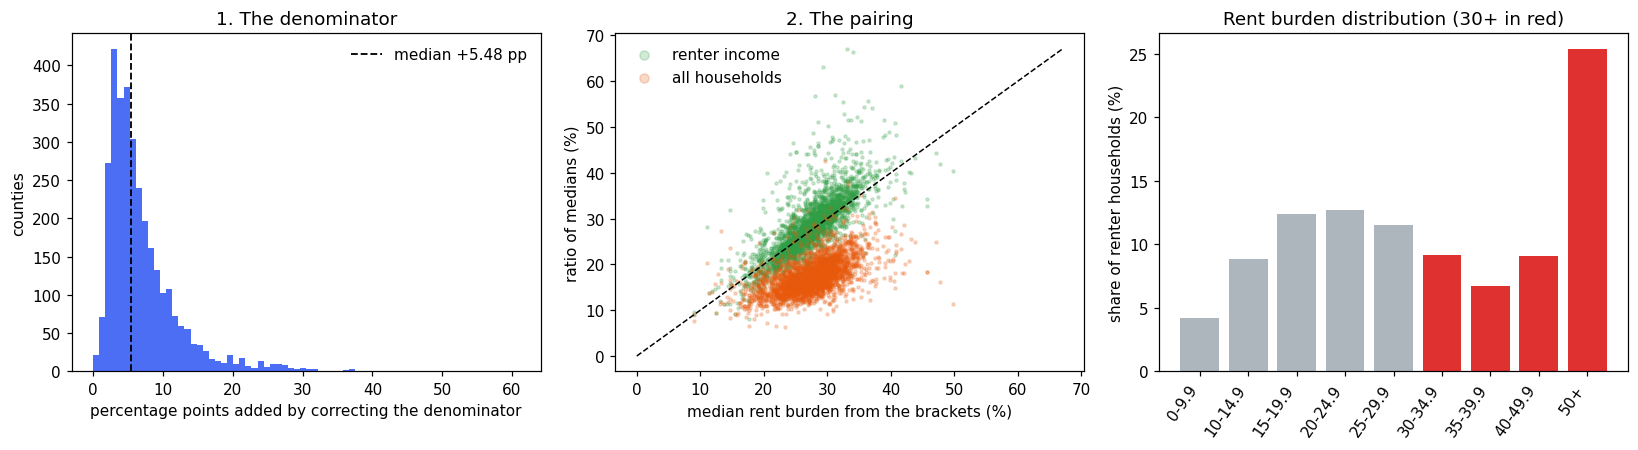

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].hist(valid.gap_pp, bins=70, color="#4c6ef5")
axes[0].axvline(valid.gap_pp.median(), color="k", ls="--", lw=1.2,
                label=f"median {valid.gap_pp.median():+.2f} pp")
axes[0].set_xlabel("percentage points added by correcting the denominator")
axes[0].set_ylabel("counties")
axes[0].set_title("1. The denominator")
axes[0].legend(frameon=False)

axes[1].scatter(pair.true_median, pair.ratio_renter, s=4, alpha=0.22, color="#2f9e44",
                label="renter income")
axes[1].scatter(pair.true_median, pair.ratio_all, s=4, alpha=0.22, color="#e8590c",
                label="all households")
_lim = [0, max(pair.true_median.max(), pair.ratio_renter.max())]
axes[1].plot(_lim, _lim, "k--", lw=1)
axes[1].set_xlabel("median rent burden from the brackets (%)")
axes[1].set_ylabel("ratio of medians (%)")
axes[1].set_title("2. The pairing")
axes[1].legend(frameon=False, markerscale=3)

_us = np.column_stack([col(states, c) for c in BRACKET_CODES]).sum(axis=0)
axes[2].bar(range(BRACKETS.n), _us / _us.sum() * 100, color="#adb5bd")
for _j in BURDENED_IDX:
    axes[2].patches[_j].set_facecolor("#e03131")
axes[2].set_xticks(range(BRACKETS.n))
axes[2].set_xticklabels(
    [f"{lo:g}+" if not np.isfinite(hi) else f"{lo:g}-{hi - 0.1:g}"
     for lo, hi in zip(BRACKETS.lower, BRACKETS.upper)], rotation=55, ha="right")
axes[2].set_ylabel("share of renter households (%)")
axes[2].set_title(f"Rent burden distribution ({BURDEN_THRESHOLD:g}+ in red)")
plt.tight_layout(); plt.show()

## 3. The aggregation

A state's published median gross rent is computed from the state's own sample. It is not built
from its counties' medians, and it cannot be recovered from them — a median is not a linear
functional, so it does not survive averaging.

That is a statement about what should happen. Below it is measured: both a simple average of
county medians and a population-weighted one are compared against the published state figure.

In [10]:
county_state_fips = counties["state"].to_numpy()
county_rent = col(counties, MEDIAN_RENT)
county_renters = col(counties, RENTER_HOUSEHOLDS)

rows = []
for _k, _fips in enumerate(states["state"].to_numpy()):
    _m = ((county_state_fips == _fips) & np.isfinite(county_rent)
          & (county_renters > 0))
    if _m.sum() < 2:
        continue
    rows.append({
        "state": states["NAME"].iloc[_k],
        "n_counties": int(_m.sum()),
        "published": col(states, MEDIAN_RENT)[_k],
        "weighted_avg": float(np.average(county_rent[_m], weights=county_renters[_m])),
        "simple_avg": float(np.mean(county_rent[_m])),
    })
agg = pd.DataFrame(rows)
agg["err_weighted"] = agg.weighted_avg - agg.published
agg["err_simple"] = agg.simple_avg - agg.published

print(f"States with at least two counties carrying a median rent: {len(agg)}")
print()
for _label, _c in (("simple average of county medians", "err_simple"),
                   ("population-weighted average", "err_weighted")):
    print(f"{_label}:")
    print(f"  median error   {agg[_c].median():+8.1f} USD")
    print(f"  mean |error|   {agg[_c].abs().mean():8.1f} USD")
    print(f"  max  |error|   {agg[_c].abs().max():8.1f} USD  "
          f"({agg.loc[agg[_c].abs().idxmax(), 'state']})")
    print(f"  states off by more than 25 USD : {int((agg[_c].abs() > 25).sum())} "
          f"of {len(agg)}")
    print()
print("Weighting by renter households removes most of the error but not all of it.")
print("The residual is the part that cannot be fixed by better weights: a median of")
print("a pooled sample is not an average of sub-sample medians at any weighting.")

States with at least two counties carrying a median rent: 51

simple average of county medians:
  median error     -180.5 USD
  mean |error|      215.2 USD
  max  |error|      479.9 USD  (Washington)
  states off by more than 25 USD : 50 of 51

population-weighted average:
  median error       +9.5 USD
  mean |error|       15.0 USD
  max  |error|       83.9 USD  (New York)
  states off by more than 25 USD : 10 of 51

Weighting by renter households removes most of the error but not all of it.
The residual is the part that cannot be fixed by better weights: a median of
a pooled sample is not an average of sub-sample medians at any weighting.


## Limitations

- **ACS 5-year estimates are period estimates** spanning 2019–2023, a window containing
  extraordinary rental-market movement and temporary federal rental assistance. The figures
  describe an average of that period and no single year within it.
- **Gross rent includes utilities where the tenant pays them**, so two households paying the same
  contract rent can record different gross rents. Cross-area comparison inherits that.
- **The 30 per cent threshold is a convention with a known critique.** It applies the same ratio at
  every income level, so it classifies a high-income household with high rent as burdened and can
  miss a low-income household below the ratio who has nothing left after rent. Residual-income
  measures address this and are not computable from this table.
- **`Not computed` is excluded, not modelled.** Households with no cash rent or non-positive income
  are removed from the base here. They are real households with real housing situations, and a
  complete analysis would describe them rather than drop them.
- **Bracket interpolation assumes uniformity within a bracket.** The median burden reported here
  inherits that assumption, and the brackets are widest exactly where the distribution is most
  skewed.
- **Medians carry margins of error that are not propagated here.** The published median rent and
  income both have margins; the ratio-of-medians comparison uses point values only, so the
  disagreement it shows is a lower bound on the total uncertainty, not the whole of it.
- **No causal claim is available.** Nothing here licenses a statement about why rent burden is
  what it is in any place.

In [11]:
"""Findings. Every number below is rendered from a value computed above."""
n_valid = len(valid)
n_pair = len(pair)

print("FINDINGS")
print("=" * 78)
print(f"0. EXTERNAL CHECK. The corrected base reproduces the Bureau's own DP04 percentage in")
print(f"   {int((np.abs(diff_corrected) <= ROUNDING_BOUND).sum()):,} of {int(comparable.sum()):,} counties "
      f"(max |difference| {np.abs(diff_corrected).max():.3f} pp, DP04 rounds to 0.1).")
print(f"   The published-total base matches in {int((np.abs(diff_naive) <= ROUNDING_BOUND).sum()):,}, "
      f"missing by a median of {np.median(diff_naive):+.2f} pp.")
print(f"1. The nine brackets plus 'Not computed' sum to the published universe exactly in")
print(f"   {sum(r.partitions for r in with_nc):,} of {len(with_nc):,} counties; the brackets alone fall short in "
      f"{sum(r.coverage is Coverage.UNDER for r in without_nc):,}.")
print(f"   'Not computed' is a median {np.nanmedian(share_nc):.1%} of the renter universe, "
      f"reaching {np.nanmax(share_nc):.0%}.")
print(f"2. Correcting the denominator raises the burdened share by a median of "
      f"{valid.gap_pp.median():.2f} pp")
print(f"   (90th percentile {valid.gap_pp.quantile(.90):.1f} pp, max "
      f"{valid.gap_pp.max():.1f} pp) and moves {int((moved_denom >= 100).sum()):,} of "
      f"{n_valid:,} counties")
print(f"   by 100 ranks or more. In {int(degenerate.sum())} counties the corrected "
      f"denominator is zero and the statistic does not exist.")
print(f"3. Ratio of medians using renter income sits {(pair.ratio_renter - pair.true_median).median():+.2f} pp "
      f"from the true median burden")
print(f"   at the median county, correlates {np.corrcoef(pair.true_median, pair.ratio_renter)[0, 1]:.3f} with it, "
      f"and still moves "
      f"{int((r_true - pair.ratio_renter.rank(ascending=False, method='first')).abs().ge(100).sum()):,} "
      f"of {n_pair:,} counties by 100+ ranks.")
print(f"4. Using all-household income instead puts the figure "
      f"{(pair.ratio_all - pair.true_median).median():+.2f} pp from the true median")
print(f"   burden and drops the correlation to "
      f"{np.corrcoef(pair.true_median, pair.ratio_all)[0, 1]:.3f}. This is the version in common use.")
print(f"5. The median rent burden falls in the open '50 percent or more' bracket in "
      f"{int(_unident.sum())} counties,")
print(f"   where it is bounded below but not identified, and is refused rather than "
      f"interpolated.")
print(f"6. A simple average of county median rents misses the published state median by a")
print(f"   median of {agg.err_simple.median():+.0f} USD; population weighting cuts that to "
      f"{agg.err_weighted.median():+.0f} USD but still")
print(f"   errs by more than 25 USD in {int((agg.err_weighted.abs() > 25).sum())} of "
      f"{len(agg)} states, peaking at "
      f"{agg.err_weighted.abs().max():.0f} USD.")
print("=" * 78)

FINDINGS
0. EXTERNAL CHECK. The corrected base reproduces the Bureau's own DP04 percentage in
   3,220 of 3,220 counties (max |difference| 0.099 pp, DP04 rounds to 0.1).
   The published-total base matches in 14, missing by a median of -5.47 pp.
1. The nine brackets plus 'Not computed' sum to the published universe exactly in
   3,222 of 3,222 counties; the brackets alone fall short in 3,218.
   'Not computed' is a median 13.4% of the renter universe, reaching 100%.
2. Correcting the denominator raises the burdened share by a median of 5.48 pp
   (90th percentile 13.2 pp, max 61.1 pp) and moves 2,485 of 3,220 counties
   by 100 ranks or more. In 2 counties the corrected denominator is zero and the statistic does not exist.
3. Ratio of medians using renter income sits +0.52 pp from the true median burden
   at the median county, correlates 0.761 with it, and still moves 2,420 of 3,181 counties by 100+ ranks.
4. Using all-household income instead puts the figure -10.18 pp from the true m

## Key Takeaways

1. Read the universe before the numerator. A published total can contain a category the statistic
   does not describe, and *Not computed* is not a low value — it is the absence of a value.
2. A denominator you construct has a margin of error you must construct too. Inheriting the
   published total's margin for a base you built out of nine brackets attaches the uncertainty of
   one quantity to another.
3. A ratio of medians is not the median of a ratio. The two describe different households, and the
   commonly published version compounds that by drawing its denominator from a wider universe than
   its numerator.
4. All three errors keep the level roughly plausible and destroy the ordering. If the deliverable
   is a ranked list, closeness at the median is not evidence that the method is adequate.
5. Refuse the percentile that falls in an open-ended bracket. It can be bounded and reported as a
   bound; reporting it as a value means reporting an assumption as a measurement.
6. A median does not survive aggregation. Weighting improves the approximation substantially and
   does not make it correct, because the quantity is not a weighted average of anything.

## Exercises

1. **Move the threshold.** Recompute the burdened share at 35 and at 50 per cent. Both are exact
   bracket edges. Then try 33 per cent, which is not, and state precisely what assumption the
   result now rests on and how large its effect is.
2. **Describe what was dropped.** The `Not computed` households are excluded here. Using `B25070`
   with `B25003` and a no-cash-rent table, characterise them: how many are no-cash-rent and how
   many report non-positive income, and what would a defensible treatment be?
3. **Propagate the medians' margins.** `B25064` and `B25119` both publish margins of error. Put
   confidence intervals on the ratio-of-medians and determine how many of the 100-plus-rank moves
   in section 2 survive them.
4. **Severe burden.** Repeat the whole analysis for the 50 per cent threshold, which is the open
   bracket. The share is still exact — explain why the share is identified when the median is not.
5. **Owners too.** `B25091` gives owner costs as a percentage of income, with a parallel structure
   and its own `Not computed`. Build the owner-side statistic and compare the size of the
   denominator effect between tenures.
6. **Reconstruct the state median properly.** Pool the county bracket counts within a state and
   interpolate the median from the pooled distribution. Does that recover the published state
   figure better than averaging county medians, and why would you expect it to?

## References

- U.S. Census Bureau. *American Community Survey 2023 5-Year Estimates*, tables **B25070**
  (gross rent as a percentage of household income), **B25064** (median gross rent), **B25119**
  (median household income by tenure), **B19013**, **B25003**.
  <https://api.census.gov/data/2023/acs/acs5/groups/B25070.json>
- U.S. Census Bureau. *Understanding and Using American Community Survey Data: What All Data Users
  Need to Know* — margins of error, derived proportions, and the treatment of medians.
- U.S. Census Bureau. *Subject Definitions* — gross rent, "not computed", and the renter-occupied
  universe.
- Joint Center for Housing Studies of Harvard University. *The State of the Nation's Housing* —
  the 30 per cent cost-burden convention and its use in practice.
- Stone, M. E. (2006). "What is Housing Affordability? The Case for the Residual Income Approach."
  *Housing Policy Debate* 17(1), 151–184 — the standard critique of ratio thresholds.
- Schwartz, M. and Wilson, E. *Who Can Afford to Live in a Home? A Look at Data from the 2006
  American Community Survey*. U.S. Census Bureau — on constructing burden measures from ACS.

In [12]:
"""Provenance records for both frames, written beside the notebook."""
#: The repository root, found by walking UP from wherever this runs. Provenance
#: used to be written to `Path.cwd() / "provenance"` in some notebooks and to a
#: repo-root-relative path in others, so the two conventions could not both be
#: satisfied by one working directory -- and a run from the wrong one silently
#: wrote sixteen records into a stray folder at the top of the repo.
REPO_ROOT = next(c for c in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (c / "src" / "krl_tutorials_data").is_dir())
out_dir = REPO_ROOT / "projects" / "08-culture-society/D27_housing_affordability_and_gentrification" / "provenance"
written = [prov_county.write(out_dir / "d27_rent_burden_county.json"),
           prov_state.write(out_dir / "d27_rent_burden_state.json"),
           prov_profile.write(out_dir / "d27_dp04_profile_county.json")]

print("Provenance written:")
for p in written:
    print(f"  {p.name}")
print()
print(f"County payload digest : {prov_county.content_sha256[:16]}...")
print(f"State payload digest  : {prov_state.content_sha256[:16]}...")
print(f"Data mode             : {prov_county.mode.value.upper()}")
print(f"Counties              : {len(counties):,}")
print(f"Bracket scheme        : {BRACKETS.n} brackets, top open-ended, "
      f"units = {BRACKETS.units}")
print(f"Burden threshold      : {BURDEN_THRESHOLD:g} (an exact bracket edge)")

Provenance written:
  d27_rent_burden_county.json
  d27_rent_burden_state.json
  d27_dp04_profile_county.json

County payload digest : 42d64fff6c221e89...
State payload digest  : fbed7278f52cabf8...
Data mode             : EMPIRICAL
Counties              : 3,222
Bracket scheme        : 9 brackets, top open-ended, units = percent of household income
Burden threshold      : 30 (an exact bracket edge)
